One 512x512 Stokes I image from all five B3 channels using NUFFT. Select GPU, run the install cell, restart the Colab runtime, then run the rest.

In [1]:
# Build GPU NUFFT
!git clone --branch KG/colab-setup https://github.com/KahaanGandhi/kine.git /content/kine
!bash /content/kine/scripts/setup_colab_nufft.sh /content/kine

Cloning into '/content/kine'...
remote: Enumerating objects: 1072, done.
remote: Counting objects: 100% (194/194), done.
remote: Compressing objects: 100% (139/139), done.
remote: Total 1072 (delta 117), reused 101 (delta 54), pack-reused 878 (from 1)
Receiving objects: 100% (1072/1072), 48.98 MiB | 19.79 MiB/s, done.
Resolving deltas: 100% (682/682), done.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libfftw3-long3:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libfftw3-long3_3.3.10-1ubuntu3_amd64.deb ...
Unpacking libfftw3-long3:amd64 (3.3.10-1ubuntu3) ...
Selecting previously unselected package libfftw3-quad3:amd64.
Preparing to unpack .../libfftw3-quad3_3.3.10-1ubuntu3_amd64.deb ...
Unpacking libfftw3-quad3:amd64 (3.3.10-1ubuntu3) ...
Selecting 

For data, `B3_input.npz` has $(u,v)$, $V_I$, and $\sigma_I$ for 3,835,102 rows.

In [1]:
"""
(1) Tell JAX to allocate GPU memory as needed
(2) Create directory in Colab runtime
(3) Tell NVIDIA driver to put its compiled GPU code cache there
Step 3 will avoid problems on HPC, but doesn't matter for Colab
"""

import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
os.makedirs('/content/cuda_cache', exist_ok=True)
os.environ['CUDA_CACHE_PATH'] = '/content/cuda_cache'

from collections import OrderedDict as odict
import time

import ehtim as eh
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import optax
from tqdm.auto import tqdm

import kine.model as mo
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi
from kine.fourier import NUFFT

from google.colab import drive
drive.mount('/content/drive')
with np.load('/content/drive/MyDrive/HLTau_B3_A100/B3_input.npz') as measurements:
    uv = measurements['uv']
    vis_i = measurements['vis_i']
    sigma_i = measurements['sigma_i']
print(f'{len(vis_i):,} B3 Stokes I visibilities; GPU: {jax.devices()[0]}')

Welcome to eht-imaging! v 1.3.2 

Mounted at /content/drive
3,835,102 B3 Stokes I visibilities; GPU: cuda:0



Use a 2-arsec field and NUFFT operator in model.

In [7]:
npix, fov_arcsec = 512, 2.0
fov = np.deg2rad(fov_arcsec / 3600)
prior = eh.image.Image(np.zeros((npix, npix)), fov / npix, 0, 0)
gpu = jax.devices('gpu')[0]

# Prepare on CPU, then move the completed inputs to the GPU
with jax.default_device(jax.devices('cpu')[0]):
    A = NUFFT.from_uv(uv, prior)
    data = {'visI': {'target': jnp.asarray(vis_i)[None, :],
                     'sigma': jnp.asarray(sigma_i)[None, :], 'A': A}}
    grid = jnp.asarray(ut.get_grid(npix, npix), dtype=jnp.float32)

    # Top-hat image is warm-start target
    short = np.argsort(np.hypot(uv[:, 0], uv[:, 1]))[:50]
    init_im = vi.Image(npix, fov, 0, 0, 150)
    init_im.add_tophat(np.median(np.abs(vis_i[short])),
                       {'fwhm': 800_000, 'blur': 100_000, 'posx': 0, 'posy': 0})
    initial = jnp.asarray(init_im.iarr, dtype=jnp.float32)

    network = mo.NeuralField(posenc_deg=(1, 1), depth=6, width=128,
                             outshift=0, scaling_i=1 / npix**2)
    variables = network.init(jax.random.PRNGKey(1), jnp.ones(2), train=True)
    schedule = optax.piecewise_constant_schedule(1e-2, {150: 0.1})
    state = tr.Trainer.create(apply_fn=network.apply,
                              params=variables['params'],
                              batch_stats=variables['batch_stats'],
                              tx=optax.adamax(schedule, eps=1e-15))

grid, data, initial, state = jax.device_put((grid, data, initial, state), gpu)

# Avoid printing everything
_ = jax.block_until_ready((grid, data, initial, state))

First fit the network to blurred top-hat.

In [3]:
warm_losses = []
for _ in tqdm(range(150), desc='Warm start'):
    loss, _, _, state = tr.Trainer.train_step(odict(state=state, grid=grid, init_arr=initial))
    warm_losses.append(float(loss))

warm_image, _ = state.apply_fn(
    {'params': state.params, 'batch_stats': state.batch_stats},
    grid, train=True, mutable=['batch_stats'])
warm_image = np.asarray(warm_image).reshape(npix, npix)

Warm start:   0%|          | 0/150 [00:00<?, ?it/s]

In [4]:
# Fit all B3 visibilities at each step
fit_losses, step_times = [], []
for _ in tqdm(range(1200), desc='Visibility fit'):
    start = time.perf_counter()
    loss, _, _, state = tr.Trainer.train_step(odict(state=state, grid=grid, data=data, lcurve=None))
    jax.block_until_ready((loss, state))
    step_times.append(time.perf_counter() - start)
    fit_losses.append(float(loss))

final_image, _ = state.apply_fn(
    {'params': state.params, 'batch_stats': state.batch_stats},
    grid, train=True, mutable=['batch_stats'])
final_image = np.asarray(final_image).reshape(npix, npix)
print(f'{1 / np.median(step_times[2:]):.1f} updates/s after compilation')

Visibility fit:   0%|          | 0/1200 [00:00<?, ?it/s]

12.7 updates/s after compilation


Compute $\chi^2_{\rm vis}=\frac{1}{2M}\sum_m |(V_{\rm pred,m}-V_{I,m})/\sigma_{I,m}|^2$ (not adjusted for number of parameters).

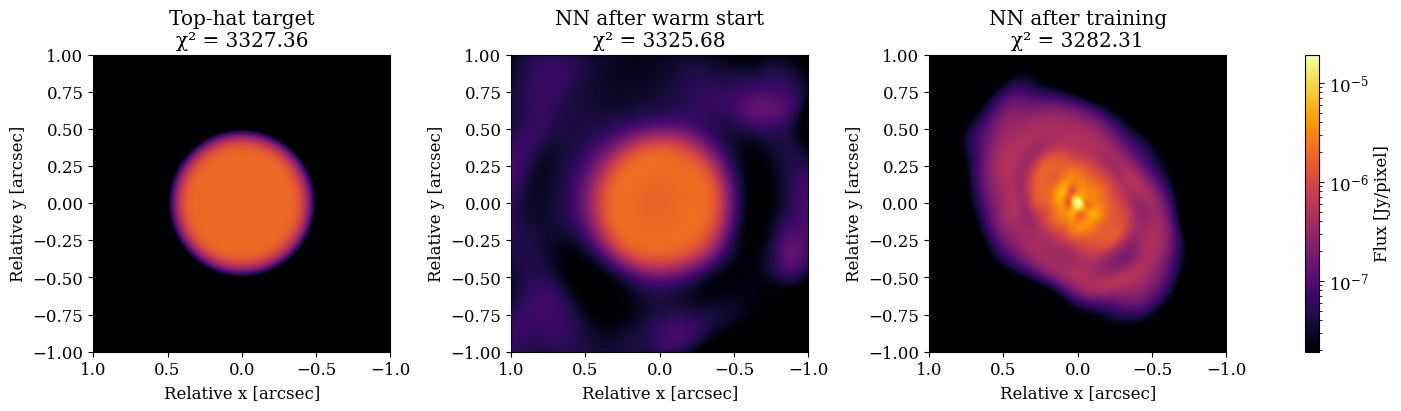

In [5]:
# Evaluate Kine's visibility χ² for each displayed image
images = [np.asarray(initial).reshape(npix, npix), warm_image, final_image]
chi2 = [float(tr.Trainer._loss_chi_nufft(image, data['visI'], 'vis'))
        for image in images]
peak = max(image.max() for image in images)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, image, title, value in zip(axes, images, ['Top-hat target', 'NN after warm start', 'NN after training'], chi2):
    ax.set_facecolor('black')
    shown = ax.imshow(image, origin='lower', extent=(1, -1, -1, 1), cmap='inferno', norm=LogNorm(vmin=peak / 1000, vmax=peak))
    ax.set(title=f'{title}\nχ² = {value:.2f}', xlabel='Relative x [arcsec]', ylabel='Relative y [arcsec]')
fig.colorbar(shown, ax=axes, label='Flux [Jy/pixel]')
fig.savefig('/content/HLTau_B3_image.png', dpi=200)
plt.show()

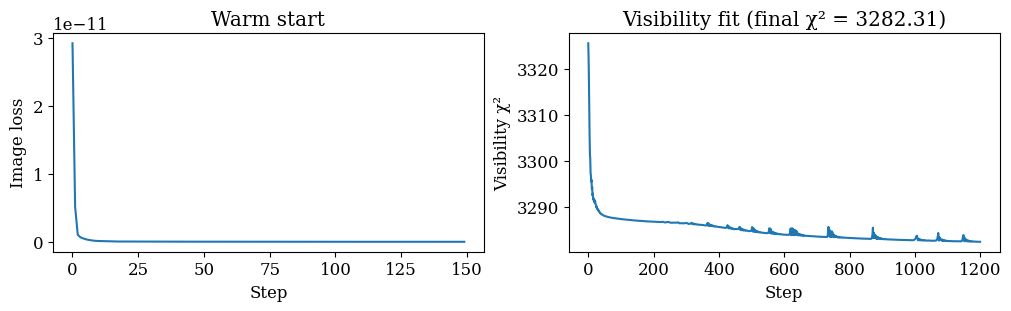

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].plot(warm_losses)
axes[0].set(title='Warm start', xlabel='Step', ylabel='Image loss')
axes[1].plot(fit_losses)
axes[1].set(title=f'Visibility fit (final χ² = {chi2[-1]:.2f})', xlabel='Step', ylabel='Visibility χ²')
fig.savefig('/content/HLTau_B3_losses.png', dpi=200)
plt.show()